# Generative AI (2311312T) — Research Paper Implementation
**Paper:** Kingma, D. P. & Welling, M. (2014). *Auto-Encoding Variational Bayes.* ICLR 2014. (arXiv:1312.6114)

**Topic:** Variational Autoencoder (VAE)  
**Name:** Nikheel C Khadakabhavi  **PRN:** 202401110020

---
### What this notebook does
1. Implements the core of the paper from scratch in PyTorch: a Gaussian encoder `q(z|x)`, the **reparameterization trick**, a Bernoulli decoder `p(x|z)` and the **SGVB / ELBO** objective with the closed-form KL term.
2. Trains it on MNIST and shows reconstructions, samples from the prior and latent interpolations.
3. Reproduces the paper's 2-D latent **manifold visualisation** (Fig. 4 of the paper).
4. Runs experiments for result analysis: latent-dimension ablation, comparison against a plain (non-variational) autoencoder, active latent units, and a downstream classification check.
5. Tries one improvement (convolutional encoder/decoder) and discusses limitations.

> **Runtime:** `Runtime → Run all`. A GPU is optional (the models are small); the whole notebook runs in a few minutes on Colab.

## 1. Theory in brief (needed to follow the code)

We want a generative model `p(x) = ∫ p(x|z) p(z) dz` with latent `z`, prior `p(z) = N(0, I)`. The true posterior `p(z|x)` is intractable, so the paper introduces a recognition model `q_φ(z|x)` and maximises the **evidence lower bound (ELBO)**:

$$\log p_\theta(x) \;\ge\; \mathcal{L}(\theta,\phi;x) = \mathbb{E}_{q_\phi(z|x)}[\log p_\theta(x|z)] \;-\; D_{KL}\big(q_\phi(z|x)\,\|\,p(z)\big)$$

* **Reconstruction term** – how well the decoder rebuilds `x` from `z`. For binary-like MNIST pixels we use a Bernoulli likelihood, i.e. binary cross-entropy.
* **KL term** – keeps the posterior close to the prior so that sampling `z ~ N(0, I)` gives meaningful images. With `q = N(μ, σ²I)` it has a closed form:  
  `KL = -½ Σ_j (1 + log σ_j² − μ_j² − σ_j²)`
* **Reparameterization trick** – instead of sampling `z ~ N(μ, σ²)` (not differentiable w.r.t. μ, σ) we sample `ε ~ N(0, I)` and set `z = μ + σ ⊙ ε`, so gradients flow through μ and σ. This is the paper's key contribution (the SGVB estimator).

In [1]:
import os, gzip, time, json, random, urllib.request
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", device)

os.makedirs("figs", exist_ok=True)
RESULTS = {}          # everything we measure is stored here and saved at the end

PyTorch 2.15.0+cu132 | device: cpu


## 2. Data — MNIST (60,000 train / 10,000 test, 28×28 grey-scale digits)

train: (60000, 784)  test: (10000, 784)  pixel range: 0.0 - 1.0


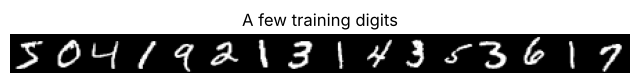

In [2]:
MIRROR = "https://raw.githubusercontent.com/golbin/TensorFlow-MNIST/master/mnist/data/"
FILES = {"train_x": "train-images-idx3-ubyte.gz", "train_y": "train-labels-idx1-ubyte.gz",
         "test_x":  "t10k-images-idx3-ubyte.gz",  "test_y":  "t10k-labels-idx1-ubyte.gz"}

def read_idx(name, is_image):
    path = os.path.join("data", FILES[name])
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(MIRROR + FILES[name], path)
    with gzip.open(path, "rb") as f:
        buf = f.read()
    arr = np.frombuffer(buf, dtype=np.uint8, offset=16 if is_image else 8)
    return arr.reshape(-1, 784) if is_image else arr

try:
    Xtr, ytr = read_idx("train_x", True), read_idx("train_y", False)
    Xte, yte = read_idx("test_x", True),  read_idx("test_y", False)
except Exception as e:                      # fallback: torchvision's own downloader
    print("Mirror failed (", e, ") -> using torchvision")
    from torchvision import datasets
    tr = datasets.MNIST("data", train=True, download=True); te = datasets.MNIST("data", train=False, download=True)
    Xtr, ytr = tr.data.numpy().reshape(-1, 784), tr.targets.numpy()
    Xte, yte = te.data.numpy().reshape(-1, 784), te.targets.numpy()

# pixels scaled to [0,1]; the whole dataset fits on the device, so we batch it manually (fast)
Xtr = torch.tensor(Xtr, dtype=torch.float32, device=device) / 255.
Xte = torch.tensor(Xte, dtype=torch.float32, device=device) / 255.
print("train:", tuple(Xtr.shape), " test:", tuple(Xte.shape), " pixel range:", Xtr.min().item(), "-", Xtr.max().item())

def show_grid(imgs, nrow, ax=None, title=None):
    # imgs: (N, 784) tensor -> one image made of an nrow-wide grid
    imgs = imgs.detach().cpu().numpy().reshape(-1, 28, 28)
    n = len(imgs); ncol = int(np.ceil(n / nrow))
    canvas = np.zeros((ncol * 28, nrow * 28))
    for i, im in enumerate(imgs):
        r, c = divmod(i, nrow)
        canvas[r*28:(r+1)*28, c*28:(c+1)*28] = im
    ax = ax or plt.gca()
    ax.imshow(canvas, cmap="gray", vmin=0, vmax=1); ax.axis("off")
    if title: ax.set_title(title)

plt.figure(figsize=(8, 2.2)); show_grid(Xtr[:16], 16, title="A few training digits"); plt.savefig("figs/00_data_samples.png", dpi=150, bbox_inches="tight"); plt.show()

## 3. Model — encoder, reparameterization, decoder

Architecture follows the paper's MNIST experiment: a single-hidden-layer MLP with **500 tanh units** for both the recognition model (encoder) and the generative model (decoder). The encoder outputs the mean and log-variance of a diagonal Gaussian; the decoder outputs Bernoulli logits (we apply `sigmoid` only when we want to see an image).

*We predict `log σ²` rather than `σ` so the network output can be any real number and σ stays positive.*

In [3]:
class VAE(nn.Module):
    # MLP VAE from the paper: x(784) -> 500 tanh -> (mu, logvar) in R^z ; z -> 500 tanh -> 784 logits
    def __init__(self, x_dim=784, h_dim=500, z_dim=20, deterministic=False):
        super().__init__()
        self.z_dim, self.deterministic = z_dim, deterministic
        self.enc_h  = nn.Linear(x_dim, h_dim)
        self.enc_mu = nn.Linear(h_dim, z_dim)
        self.enc_lv = nn.Linear(h_dim, z_dim)
        self.dec_h  = nn.Linear(z_dim, h_dim)
        self.dec_o  = nn.Linear(h_dim, x_dim)

    def encode(self, x):
        h = torch.tanh(self.enc_h(x))
        return self.enc_mu(h), self.enc_lv(h)

    def reparameterize(self, mu, logvar):
        if self.deterministic:                  # plain autoencoder baseline: no noise
            return mu
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)             # eps ~ N(0, I)
        return mu + eps * std                   # z = mu + sigma * eps   (reparameterization trick)

    def decode(self, z):
        return self.dec_o(torch.tanh(self.dec_h(z)))      # logits of Bernoulli means

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar


def loss_terms(logits, x, mu, logvar):
    # negative ELBO split into its two parts, both summed over the batch
    recon = F.binary_cross_entropy_with_logits(logits, x, reduction="sum")     # -E_q[log p(x|z)]
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())               # KL(q(z|x) || N(0,I))
    return recon, kl

m = VAE().to(device)
print(m)
print("trainable parameters:", sum(p.numel() for p in m.parameters()))

VAE(
  (enc_h): Linear(in_features=784, out_features=500, bias=True)
  (enc_mu): Linear(in_features=500, out_features=20, bias=True)
  (enc_lv): Linear(in_features=500, out_features=20, bias=True)
  (dec_h): Linear(in_features=20, out_features=500, bias=True)
  (dec_o): Linear(in_features=500, out_features=784, bias=True)
)
trainable parameters: 815824


## 4. Training and evaluation utilities
Loss reported everywhere = **negative ELBO per image in nats** (lower is better) = reconstruction + KL.
Optimiser: Adam, lr = 1e-3, batch size 128. (The paper used Adagrad; Adam is the modern default and gives the same behaviour here.)

In [4]:
BATCH, LR = 128, 1e-3

@torch.no_grad()
def evaluate(model, X, seed=0):
    # average recon / KL / -ELBO per image over a dataset, one z-sample per image (fixed seed => repeatable)
    model.eval(); g_state = torch.get_rng_state(); torch.manual_seed(seed)
    R = K = 0.0
    for i in range(0, len(X), 2000):
        xb = X[i:i+2000]; logits, mu, lv = model(xb)
        r, k = loss_terms(logits, xb, mu, lv); R += r.item(); K += k.item()
    torch.set_rng_state(g_state)
    n = len(X); return R / n, K / n, (R + K) / n

def train(model, epochs, use_kl=True, name="model", log_every=5):
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    hist = {"train": [], "test": [], "recon": [], "kl": []}
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); perm = torch.randperm(len(Xtr), device=device); tot = 0.0
        for i in range(0, len(Xtr), BATCH):
            xb = Xtr[perm[i:i+BATCH]]
            logits, mu, lv = model(xb)
            recon, kl = loss_terms(logits, xb, mu, lv)
            loss = (recon + kl if use_kl else recon) / len(xb)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += (recon + kl).item()
        r, k, te = evaluate(model, Xte)
        hist["train"].append(tot / len(Xtr)); hist["test"].append(te); hist["recon"].append(r); hist["kl"].append(k)
        if ep == 1 or ep % log_every == 0 or ep == epochs:
            print(f"[{name}] epoch {ep:3d}/{epochs}  train -ELBO {hist['train'][-1]:7.2f}  test -ELBO {te:7.2f}  (recon {r:6.2f} + KL {k:5.2f})")
    hist["seconds"] = time.time() - t0
    return hist

## 5. Main experiment — VAE with a 20-dimensional latent space

In [5]:
EPOCHS_MAIN = 30
torch.manual_seed(SEED)
vae = VAE(z_dim=20).to(device)
h_main = train(vae, EPOCHS_MAIN, name="VAE z=20")
RESULTS["main"] = {"test_neg_elbo": h_main["test"][-1], "recon": h_main["recon"][-1], "kl": h_main["kl"][-1],
                   "train_neg_elbo": h_main["train"][-1], "train_seconds": h_main["seconds"], "epochs": EPOCHS_MAIN}
print("\nFinal test -ELBO: %.2f nats/image  (= %.4f bits per pixel)" % (h_main["test"][-1], h_main["test"][-1] / (784 * np.log(2))))

[VAE z=20] epoch   1/30  train -ELBO  158.37  test -ELBO  128.12  (recon 102.79 + KL 25.33)


[VAE z=20] epoch   5/30  train -ELBO  113.67  test -ELBO  111.63  (recon  86.13 + KL 25.50)


[VAE z=20] epoch  10/30  train -ELBO  107.45  test -ELBO  106.66  (recon  80.79 + KL 25.87)


[VAE z=20] epoch  15/30  train -ELBO  105.23  test -ELBO  104.59  (recon  79.16 + KL 25.43)


[VAE z=20] epoch  20/30  train -ELBO  104.03  test -ELBO  103.75  (recon  77.77 + KL 25.98)


[VAE z=20] epoch  25/30  train -ELBO  103.23  test -ELBO  103.04  (recon  77.15 + KL 25.89)


[VAE z=20] epoch  30/30  train -ELBO  102.64  test -ELBO  102.75  (recon  77.79 + KL 24.97)

Final test -ELBO: 102.75 nats/image  (= 0.1891 bits per pixel)


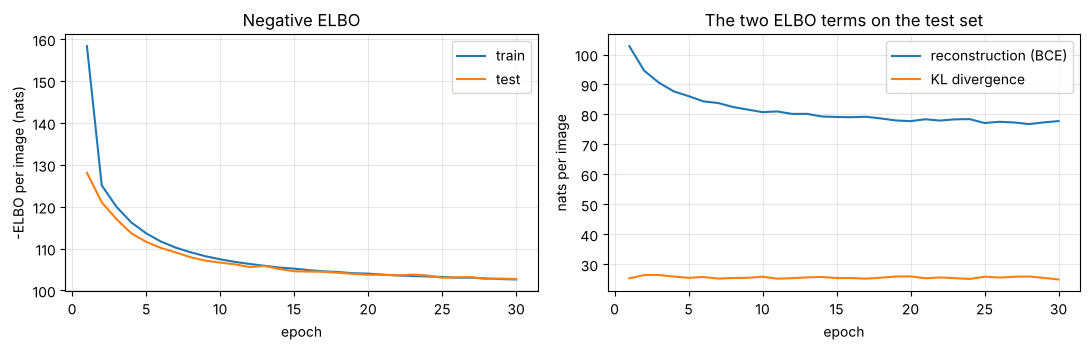

In [6]:
# Training curves
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ep = np.arange(1, EPOCHS_MAIN + 1)
ax[0].plot(ep, h_main["train"], label="train"); ax[0].plot(ep, h_main["test"], label="test")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("-ELBO per image (nats)"); ax[0].set_title("Negative ELBO"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(ep, h_main["recon"], label="reconstruction (BCE)"); ax[1].plot(ep, h_main["kl"], label="KL divergence")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("nats per image"); ax[1].set_title("The two ELBO terms on the test set"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("figs/01_training_curves.png", dpi=150); plt.show()

### 5.1 Reconstructions  (top row: original test digits, bottom row: VAE reconstruction)

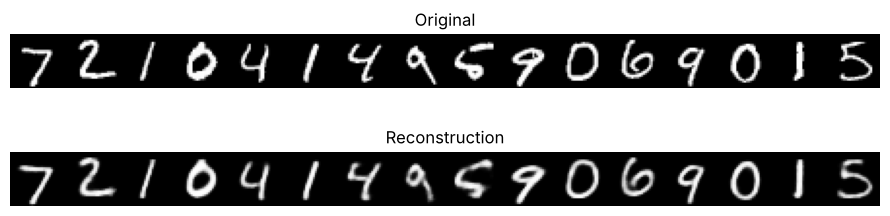

In [7]:
vae.eval()
with torch.no_grad():
    x = Xte[:16]; mu, lv = vae.encode(x); recon = torch.sigmoid(vae.decode(mu))   # decode the posterior mean
fig, ax = plt.subplots(2, 1, figsize=(9, 2.8))
show_grid(x, 16, ax[0], "Original"); show_grid(recon, 16, ax[1], "Reconstruction")
plt.tight_layout(); plt.savefig("figs/02_reconstructions.png", dpi=150); plt.show()

### 5.2 Generation — sample `z ~ N(0, I)` and decode (this is what makes a VAE a *generative* model)

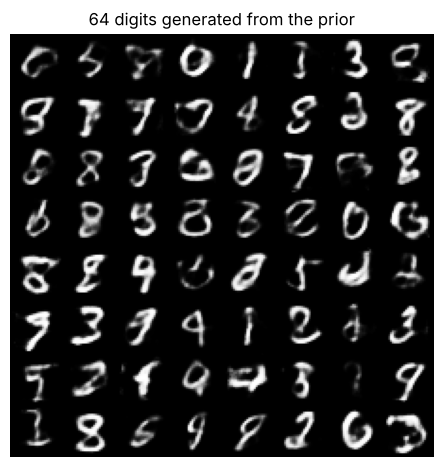

In [8]:
torch.manual_seed(1)
with torch.no_grad():
    z = torch.randn(64, 20, device=device); samples = torch.sigmoid(vae.decode(z))
plt.figure(figsize=(5.5, 5.5)); show_grid(samples, 8, title="64 digits generated from the prior")
plt.savefig("figs/03_samples_vae.png", dpi=150, bbox_inches="tight"); plt.show()

### 5.3 Latent-space interpolation — walk in a straight line between the codes of two real digits

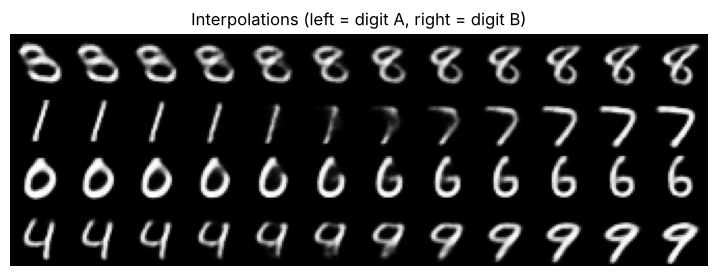

In [9]:
def interpolate(model, xa, xb, steps=12):
    with torch.no_grad():
        za, _ = model.encode(xa[None]); zb, _ = model.encode(xb[None])
        t = torch.linspace(0, 1, steps, device=device)[:, None]
        return torch.sigmoid(model.decode((1 - t) * za + t * zb))

pairs = []
for a, b in [(3, 8), (1, 7), (0, 6), (4, 9)]:          # digit class pairs
    ia = int((torch.tensor(yte) == a).nonzero()[0]); ib = int((torch.tensor(yte) == b).nonzero()[1])
    pairs.append((ia, ib))
rows = torch.cat([interpolate(vae, Xte[i], Xte[j]) for i, j in pairs])
plt.figure(figsize=(9, 3.2)); show_grid(rows, 12, title="Interpolations (left = digit A, right = digit B)")
plt.savefig("figs/04_interpolation.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Reproducing the paper's 2-D manifold (Fig. 4)
With only **2 latent dimensions** we can *see* the latent space. We (a) plot the encoder means of test digits coloured by class, and (b) decode a regular grid of `z` values (spaced by the inverse CDF of the Gaussian prior, as in the paper) to visualise the learned data manifold.

[VAE z=2] epoch   1/30  train -ELBO  188.21  test -ELBO  174.69  (recon 169.18 + KL  5.51)


[VAE z=2] epoch   5/30  train -ELBO  160.73  test -ELBO  159.57  (recon 153.92 + KL  5.66)


[VAE z=2] epoch  10/30  train -ELBO  153.25  test -ELBO  153.70  (recon 147.34 + KL  6.36)


[VAE z=2] epoch  15/30  train -ELBO  150.30  test -ELBO  151.10  (recon 144.91 + KL  6.19)


[VAE z=2] epoch  20/30  train -ELBO  148.53  test -ELBO  150.15  (recon 143.93 + KL  6.22)


[VAE z=2] epoch  25/30  train -ELBO  147.27  test -ELBO  149.14  (recon 142.90 + KL  6.23)


[VAE z=2] epoch  30/30  train -ELBO  146.34  test -ELBO  148.82  (recon 142.43 + KL  6.39)


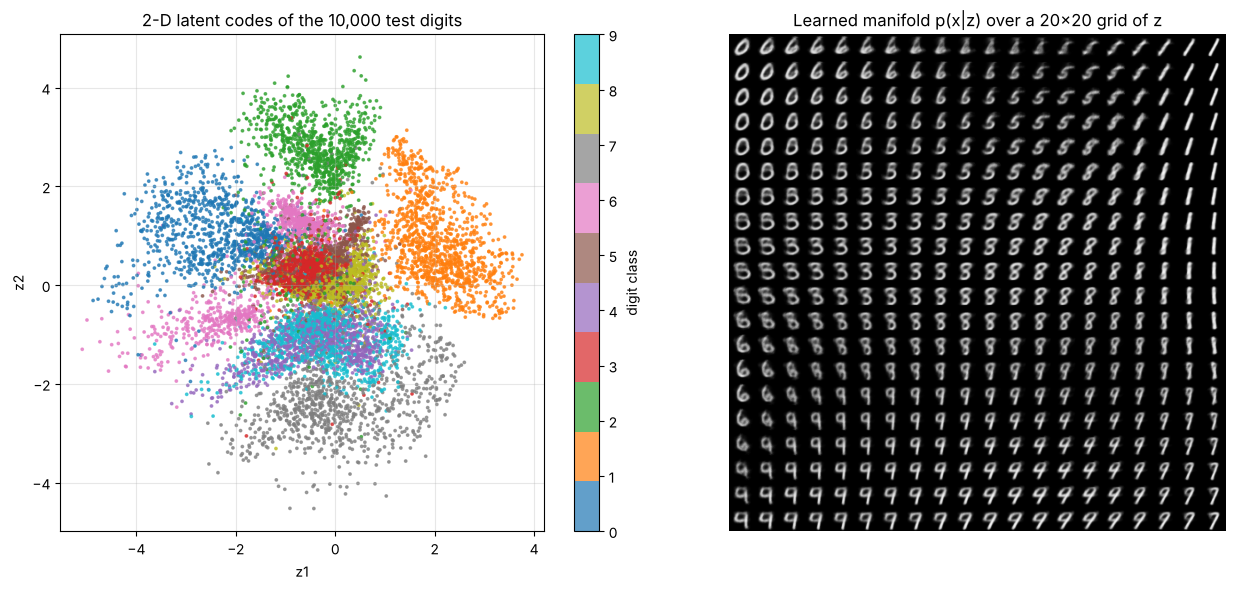

In [10]:
torch.manual_seed(SEED)
vae2 = VAE(z_dim=2).to(device)
h_2d = train(vae2, 30, name="VAE z=2")
RESULTS["z2"] = {"test_neg_elbo": h_2d["test"][-1], "recon": h_2d["recon"][-1], "kl": h_2d["kl"][-1]}

with torch.no_grad():
    mu2, _ = vae2.encode(Xte); mu2 = mu2.cpu().numpy()
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
sc = ax[0].scatter(mu2[:, 0], mu2[:, 1], c=yte, cmap="tab10", s=3, alpha=.7)
ax[0].set_xlabel("z1"); ax[0].set_ylabel("z2"); ax[0].set_title("2-D latent codes of the 10,000 test digits"); ax[0].grid(alpha=.3)
cb = plt.colorbar(sc, ax=ax[0], ticks=range(10)); cb.set_label("digit class")

N = 20
u = torch.linspace(0.05, 0.95, N); zs = torch.distributions.Normal(0, 1).icdf(u)      # inverse-CDF grid
grid = torch.stack([torch.tensor([a, b]) for b in reversed(zs.tolist()) for a in zs.tolist()]).float().to(device)
with torch.no_grad(): imgs = torch.sigmoid(vae2.decode(grid))
show_grid(imgs, N, ax[1], "Learned manifold p(x|z) over a 20x20 grid of z")
plt.tight_layout(); plt.savefig("figs/05_latent_2d.png", dpi=150); plt.show()

## 7. Result analysis

### 7.1 Latent dimensionality ablation
How does the size of `z` change the bound? (15 epochs each to keep it quick.)

[z=2] epoch   1/15  train -ELBO  188.21  test -ELBO  174.69  (recon 169.18 + KL  5.51)


[z=2] epoch  15/15  train -ELBO  150.30  test -ELBO  151.10  (recon 144.91 + KL  6.19)


[z=5] epoch   1/15  train -ELBO  168.27  test -ELBO  147.93  (recon 136.46 + KL 11.47)


[z=5] epoch  15/15  train -ELBO  122.53  test -ELBO  122.59  (recon 110.69 + KL 11.90)


[z=10] epoch   1/15  train -ELBO  159.13  test -ELBO  135.60  (recon 117.92 + KL 17.68)


[z=10] epoch  15/15  train -ELBO  108.18  test -ELBO  107.78  (recon  89.60 + KL 18.18)


[z=20] epoch   1/15  train -ELBO  158.37  test -ELBO  128.12  (recon 102.79 + KL 25.33)


[z=20] epoch  15/15  train -ELBO  105.23  test -ELBO  104.59  (recon  79.16 + KL 25.43)


[z=50] epoch   1/15  train -ELBO  168.51  test -ELBO  136.09  (recon 109.60 + KL 26.49)


[z=50] epoch  15/15  train -ELBO  105.93  test -ELBO  105.12  (recon  78.08 + KL 27.05)

 z_dim | test -ELBO | recon  |   KL
     2 |    151.10  | 144.91 |  6.19
     5 |    122.59  | 110.69 | 11.90
    10 |    107.78  |  89.60 | 18.18
    20 |    104.59  |  79.16 | 25.43
    50 |    105.12  |  78.08 | 27.05


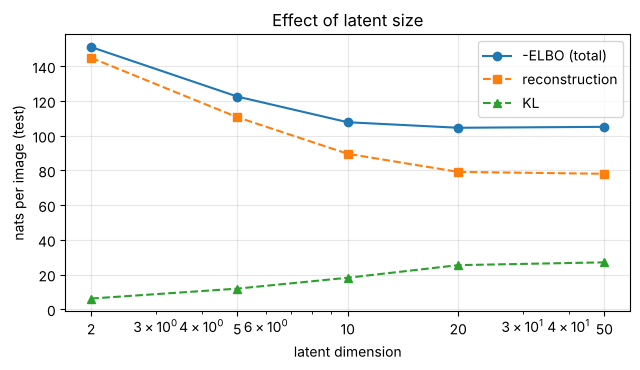

In [11]:
DIMS, EPOCHS_ABL = [2, 5, 10, 20, 50], 15
abl = {}
for d in DIMS:
    torch.manual_seed(SEED)
    mdl = VAE(z_dim=d).to(device)
    h = train(mdl, EPOCHS_ABL, name=f"z={d}", log_every=EPOCHS_ABL)
    abl[d] = {"test_neg_elbo": h["test"][-1], "recon": h["recon"][-1], "kl": h["kl"][-1]}
RESULTS["ablation_latent_dim"] = {str(d): v for d, v in abl.items()}

print("\n z_dim | test -ELBO | recon  |   KL")
for d in DIMS: print(f"  {d:4d} | {abl[d]['test_neg_elbo']:9.2f}  | {abl[d]['recon']:6.2f} | {abl[d]['kl']:5.2f}")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(DIMS, [abl[d]["test_neg_elbo"] for d in DIMS], "o-", label="-ELBO (total)")
ax.plot(DIMS, [abl[d]["recon"] for d in DIMS], "s--", label="reconstruction")
ax.plot(DIMS, [abl[d]["kl"] for d in DIMS], "^--", label="KL")
ax.set_xscale("log"); ax.set_xticks(DIMS); ax.set_xticklabels(DIMS)
ax.set_xlabel("latent dimension"); ax.set_ylabel("nats per image (test)"); ax.set_title("Effect of latent size"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("figs/06_latent_dim_ablation.png", dpi=150); plt.show()

### 7.2 How many latent dimensions are actually used? (active units)
Following Burda et al. (IWAE, 2016), a latent unit is *active* if `Var_x[ E_q(z|x)[z_j] ] > 0.01`. Units that never deviate from the prior are "collapsed" — the model ignores them.

[z=50] epoch   1/15  train -ELBO  168.51  test -ELBO  136.09  (recon 109.60 + KL 26.49)


[z=50] epoch  15/15  train -ELBO  105.93  test -ELBO  105.12  (recon  78.08 + KL 27.05)
z=20: 20/20 active   |   z=50: 32/50 active


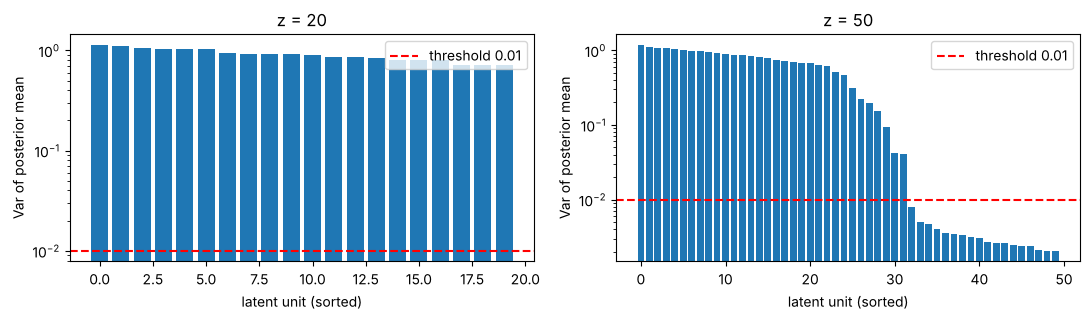

In [12]:
def active_units(model, X, thr=0.01):
    with torch.no_grad(): mu, _ = model.encode(X)
    v = mu.var(dim=0); return int((v > thr).sum()), v.cpu().numpy()

torch.manual_seed(SEED)
vae50 = VAE(z_dim=50).to(device); _ = train(vae50, 15, name="z=50", log_every=15)
au20, v20 = active_units(vae, Xte); au50, v50 = active_units(vae50, Xte)
print(f"z=20: {au20}/20 active   |   z=50: {au50}/50 active")
RESULTS["active_units"] = {"z20": [au20, 20], "z50": [au50, 50]}

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
for a, v, t in [(ax[0], v20, "z = 20"), (ax[1], v50, "z = 50")]:
    a.bar(range(len(v)), np.sort(v)[::-1]); a.axhline(0.01, color="r", ls="--", label="threshold 0.01")
    a.set_yscale("log"); a.set_xlabel("latent unit (sorted)"); a.set_ylabel("Var of posterior mean"); a.set_title(t); a.legend()
plt.tight_layout(); plt.savefig("figs/07_active_units.png", dpi=150); plt.show()

### 7.3 Why the KL term matters — VAE vs. a plain autoencoder
The baseline has the **same architecture** but no noise and no KL term (`z = μ`, loss = reconstruction only). Both reconstruct well; the question is whether we can *sample* from them.

[AE z=20] epoch   1/15  train -ELBO  380.18  test -ELBO  290.84  (recon  95.71 + KL 195.14)


[AE z=20] epoch  15/15  train -ELBO  151.54  test -ELBO  149.38  (recon  66.33 + KL 83.05)


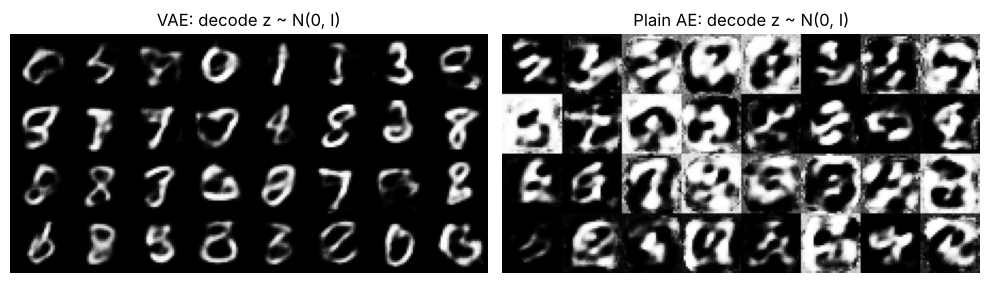

AE latent std per dim (mean): 2.29   |  VAE posterior-mean std (mean): 0.95
AE reconstruction BCE (test): 66.33  vs  VAE reconstruction BCE: 77.79


In [13]:
torch.manual_seed(SEED)
ae = VAE(z_dim=20, deterministic=True).to(device)
h_ae = train(ae, 15, use_kl=False, name="AE z=20", log_every=15)
torch.manual_seed(1)
with torch.no_grad():
    z = torch.randn(32, 20, device=device)
    s_vae = torch.sigmoid(vae.decode(z)); s_ae = torch.sigmoid(ae.decode(z))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
show_grid(s_vae, 8, ax[0], "VAE: decode z ~ N(0, I)"); show_grid(s_ae, 8, ax[1], "Plain AE: decode z ~ N(0, I)")
plt.tight_layout(); plt.savefig("figs/08_vae_vs_ae_samples.png", dpi=150); plt.show()
r_ae, _, _ = evaluate(ae, Xte)
with torch.no_grad(): mu_ae, _ = ae.encode(Xte); print("AE latent std per dim (mean): %.2f   |  VAE posterior-mean std (mean): %.2f" % (mu_ae.std(0).mean(), vae.encode(Xte)[0].std(0).mean()))
RESULTS["ae_baseline"] = {"test_recon_bce": r_ae, "latent_std_mean": float(mu_ae.std(0).mean())}
print("AE reconstruction BCE (test): %.2f  vs  VAE reconstruction BCE: %.2f" % (r_ae, h_main["recon"][-1]))

### 7.4 Is the latent code useful? (linear classification on the 20-D means)
A logistic-regression classifier is trained on the encoder means of 10,000 training digits and tested on all 10,000 test digits. It uses **only 20 numbers per image** instead of 784 pixels.

In [14]:
with torch.no_grad():
    ztr, _ = vae.encode(Xtr[:10000]); zte, _ = vae.encode(Xte)
clf = LogisticRegression(max_iter=3000).fit(ztr.cpu().numpy(), ytr[:10000])
acc = clf.score(zte.cpu().numpy(), yte)
print(f"Linear classifier on 20-D VAE latent: {acc*100:.2f}% test accuracy")
RESULTS["latent_classification_acc"] = acc

Linear classifier on 20-D VAE latent: 89.10% test accuracy


## 8. Improvement experiment — convolutional encoder/decoder
One limitation of the paper's MLP is that it ignores image structure. We swap in a small CNN (2 strided conv layers → 20-D latent → 2 transposed-conv layers) and keep the loss, prior and training loop unchanged.

[ConvVAE z=20] epoch   1/15  train -ELBO  167.26  test -ELBO  117.84  (recon  93.66 + KL 24.18)


[ConvVAE z=20] epoch   5/15  train -ELBO  105.19  test -ELBO  104.33  (recon  78.35 + KL 25.98)


[ConvVAE z=20] epoch  10/15  train -ELBO  102.16  test -ELBO  101.70  (recon  75.50 + KL 26.20)


[ConvVAE z=20] epoch  15/15  train -ELBO  100.66  test -ELBO  100.48  (recon  73.64 + KL 26.84)


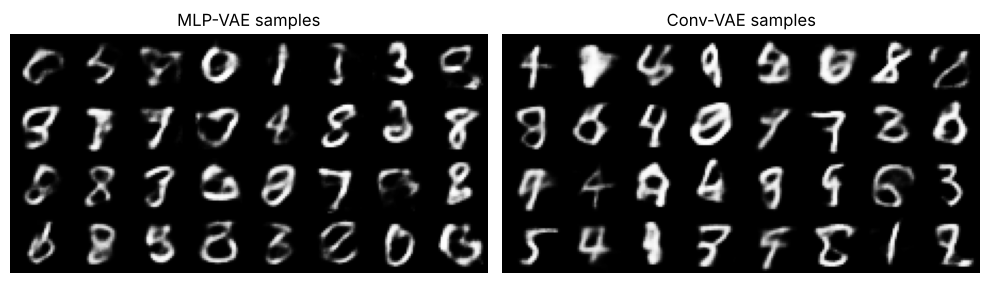

In [15]:
class ConvVAE(nn.Module):
    def __init__(self, z_dim=20):
        super().__init__()
        self.z_dim = z_dim
        self.conv = nn.Sequential(nn.Conv2d(1, 32, 4, 2, 1), nn.ReLU(), nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU())   # 28->14->7
        self.mu, self.lv = nn.Linear(64 * 49, z_dim), nn.Linear(64 * 49, z_dim)
        self.fc = nn.Linear(z_dim, 64 * 49)
        self.deconv = nn.Sequential(nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(), nn.ConvTranspose2d(32, 1, 4, 2, 1))   # 7->14->28
    def encode(self, x):
        h = self.conv(x.view(-1, 1, 28, 28)).flatten(1); return self.mu(h), self.lv(h)
    def reparameterize(self, mu, lv): return mu + torch.randn_like(mu) * torch.exp(0.5 * lv)
    def decode(self, z): return self.deconv(F.relu(self.fc(z)).view(-1, 64, 7, 7)).flatten(1)
    def forward(self, x):
        mu, lv = self.encode(x); return self.decode(self.reparameterize(mu, lv)), mu, lv

torch.manual_seed(SEED)
cvae = ConvVAE(20).to(device)
h_cv = train(cvae, 15, name="ConvVAE z=20", log_every=5)
RESULTS["conv_vae"] = {"test_neg_elbo": h_cv["test"][-1], "recon": h_cv["recon"][-1], "kl": h_cv["kl"][-1], "train_seconds": h_cv["seconds"]}

torch.manual_seed(1)
with torch.no_grad(): s_cv = torch.sigmoid(cvae.decode(torch.randn(32, 20, device=device)))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
show_grid(s_vae, 8, ax[0], "MLP-VAE samples"); show_grid(s_cv, 8, ax[1], "Conv-VAE samples")
plt.tight_layout(); plt.savefig("figs/09_mlp_vs_conv_samples.png", dpi=150); plt.show()

## 9. Summary table and saved results

In [16]:
rows = [("MLP-VAE, z=20 (30 ep)", RESULTS["main"]["test_neg_elbo"], RESULTS["main"]["recon"], RESULTS["main"]["kl"]),
        ("MLP-VAE, z=2  (30 ep)", RESULTS["z2"]["test_neg_elbo"], RESULTS["z2"]["recon"], RESULTS["z2"]["kl"]),
        ("Conv-VAE, z=20 (15 ep)", RESULTS["conv_vae"]["test_neg_elbo"], RESULTS["conv_vae"]["recon"], RESULTS["conv_vae"]["kl"])]
print(f"{'model':28s} {'-ELBO':>8s} {'recon':>8s} {'KL':>7s}")
for n, a, b, c in rows: print(f"{n:28s} {a:8.2f} {b:8.2f} {c:7.2f}")
json.dump(RESULTS, open("results.json", "w"), indent=2)
print("\nSaved results.json and the figures in ./figs")

model                           -ELBO    recon      KL
MLP-VAE, z=20 (30 ep)          102.75    77.79   24.97
MLP-VAE, z=2  (30 ep)          148.82   142.43    6.39
Conv-VAE, z=20 (15 ep)         100.48    73.64   26.84

Saved results.json and the figures in ./figs


## 10. Limitations and possible improvements

| Limitation observed | Why it happens | Possible improvement |
|---|---|---|
| Blurry reconstructions / samples | Pixel-wise Bernoulli (or Gaussian) likelihood averages over plausible images; ELBO rewards the mean image | Better decoders (PixelCNN decoder), perceptual / adversarial loss (VAE-GAN), diffusion decoders |
| Posterior is a diagonal Gaussian, prior is `N(0,I)` | Needed for closed-form KL and cheap sampling, but too simple for multimodal data | Normalizing-flow posteriors (IAF), learned/mixture priors (VampPrior), hierarchical VAEs |
| Only a lower bound on `log p(x)`, can be loose | Gap = `KL(q(z\|x) \|\| p(z\|x))` | Importance-weighted VAE (IWAE) for a tighter bound |
| Posterior collapse / inactive units | KL pushes unused dimensions to the prior (Section 7.2) | KL annealing, free bits, β < 1 |
| No control over *what* each dimension means | Isotropic prior does not force disentanglement | β-VAE, FactorVAE, conditional VAE for supervised control |
| MLP ignores image structure | Fully connected layers | Convolutional/ResNet encoder–decoder (Section 8), VQ-VAE for discrete latents |

## References
1. D. P. Kingma, M. Welling. *Auto-Encoding Variational Bayes.* ICLR 2014. arXiv:1312.6114.
2. Y. Burda, R. Grosse, R. Salakhutdinov. *Importance Weighted Autoencoders.* ICLR 2016 (active-unit measure).
3. I. Higgins et al. *β-VAE.* ICLR 2017.
4. Y. LeCun et al. *Gradient-based learning applied to document recognition* (MNIST). Proc. IEEE, 1998.